<a href="https://colab.research.google.com/github/PaigeLaybourn-Morris/mortgage-data-fairness-analysis/blob/main/bond_valuation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
def calculate_bond_price(face_value, coupon_rate, yield_rate, maturity):
    """
    Calculate the theoretical price of a bond.

    Rates should be entered as decimals:
    5% = 0.05
    """
    annual_coupon = face_value * coupon_rate

    coupon_values = sum(
        annual_coupon / (1 + yield_rate)**t
        for t in range(1, maturity + 1)
    )

    redemption_value = face_value / (1 + yield_rate)**maturity

    return coupon_values + redemption_value


price = calculate_bond_price(
    face_value=1000,
    coupon_rate=0.05,
    yield_rate=0.04,
    maturity=5
)

print(f"Bond price: £{price:.2f}")

Bond price: £1044.52


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

yields = np.arange(0.01, 0.101, 0.01)

results = []

for yield_rate in yields:
    price = calculate_bond_price(
        face_value=1000,
        coupon_rate=0.05,
        yield_rate=yield_rate,
        maturity=5
    )

    results.append({
        "Yield (%)": yield_rate * 100,
        "Bond Price (£)": price
    })

df = pd.DataFrame(results)

print(df.round(2).to_string(index=False))

 Yield (%)  Bond Price (£)
       1.0         1194.14
       2.0         1141.40
       3.0         1091.59
       4.0         1044.52
       5.0         1000.00
       6.0          957.88
       7.0          918.00
       8.0          880.22
       9.0          844.41
      10.0          810.46


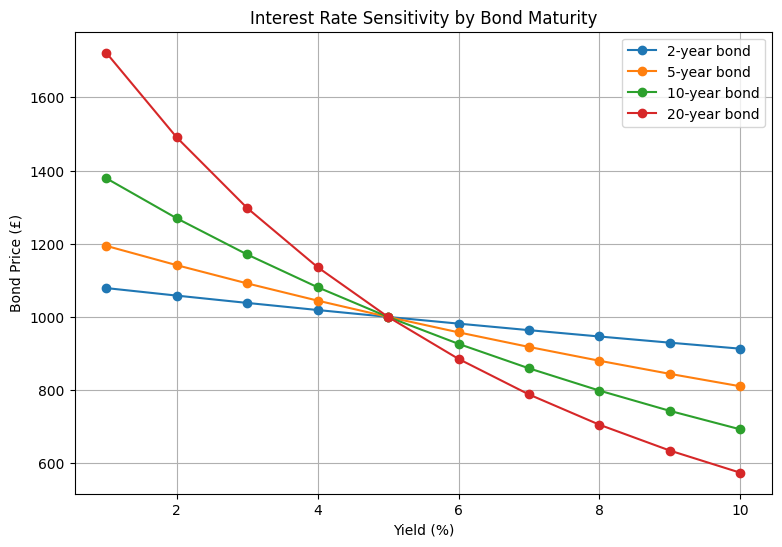

In [4]:
maturities = [2, 5, 10, 20]
yields = np.arange(0.01, 0.101, 0.01)

plt.figure(figsize=(9, 6))

for maturity in maturities:
    prices = [
        calculate_bond_price(
            face_value=1000,
            coupon_rate=0.05,
            yield_rate=y,
            maturity=maturity
        )
        for y in yields
    ]

    plt.plot(
        yields * 100,
        prices,
        marker="o",
        label=f"{maturity}-year bond"
    )

plt.xlabel("Yield (%)")
plt.ylabel("Bond Price (£)")
plt.title("Interest Rate Sensitivity by Bond Maturity")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
coupon_rates = [0.02, 0.05, 0.08]
yield_rate = 0.05
maturity = 10

for coupon_rate in coupon_rates:
    price = calculate_bond_price(
        face_value=1000,
        coupon_rate=coupon_rate,
        yield_rate=yield_rate,
        maturity=maturity
    )

    print(
        f"Coupon rate: {coupon_rate:.0%} | "
        f"Bond price: £{price:.2f}"
    )

Coupon rate: 2% | Bond price: £768.35
Coupon rate: 5% | Bond price: £1000.00
Coupon rate: 8% | Bond price: £1231.65
